<font size = 3 color="gray">Máster Universitario en inteligencia artificial (MUIA)</font> 

# Red neuronal sencilla

Red neuronal para aprender los distintos pasos del aprendizaje.
La red consiste en una capa de entrada de dos neuronas, una capa oculta de cuatro neuronas con función de activación sigmoidea o ReLU 
y una capa de salida con función sigmoidea.


## Importación de librerías

Cargamos las librerías necesarias: `numpy` para cálculo numérico, `matplotlib` para gráficas, `copy` para copias profundas de estructuras de datos y `random` para barajar los datos en cada época.

In [435]:
%config InlineBackend.figure_format = 'retina'
import matplotlib.pyplot as plt
import numpy as np
import copy
import random

## Funciones auxiliares

Definimos dos funciones que usaremos a lo largo del notebook:

- **`crea_datos(numpuntos)`**: genera puntos aleatorios $(x, y)$ en $[0,1]^2$ y les asigna una etiqueta binaria (0 o 1) según una regla geométrica. Se pueden activar distintas fronteras de decisión (recta, circunferencia, o tres regiones) comentando/descomentando las líneas correspondientes.
- **`plot_data(data, plabels)`**: dibuja los puntos coloreados por clase (azul = clase 0, verde = clase 1). Si se pasan predicciones, los errores de clasificación se pintan en rojo.

In [436]:
def random_init(longitud):
    """Devuelve un array de 'longitud' valores aleatorios con distribución N(0,1)."""
    return (np.random.randn(longitud))

def crea_datos(numpuntos):
    """Genera numpuntos muestras (x, y) aleatorias """
    inputs = [np.array(np.random.rand(numpuntos))]  # Fila 0, valores x
    inputs.append(np.random.rand(numpuntos))        # Fila 1, valores y   
    inputs.append(np.zeros(numpuntos))              # Fila 2, etiquetas
    for i in range(numpuntos):
        #inputs[2][i] = ((inputs[1][i]+inputs[0][i])<1)             # Linea recta
        #inputs[2][i] = ((inputs[1][i]**2+inputs[0][i]**2))<0.5      # Circunferencia
        inputs[2][i] = ((inputs[1][i]**2+inputs[0][i]**2)<0.7**2)  or (inputs[0][i]>0.9) #Tres regiones
        
    return inputs

In [437]:
def plot_data(data, plabels=""):
    """Dibuja los puntos del conjunto de datos coloreados por clase.
    Si se pasan plabels (predicciones), colorea según ellas: azul=0, verde=1, rojo=error."""
    fig = plt.figure(figsize=(5,5))
    ax = fig.add_subplot(111)
    cols=["blue","green","red"]
    for v in range(3):
        dplot = data[data[:,2]==v]
        if len(plabels)==0:
            pass 
        else:
            dplot = data[plabels==v]
        ax.scatter(dplot[:,0], dplot[:,1], color=cols[v], s=10,  zorder=50)
    nudge = 0.02
    ax.set_aspect('equal', 'datalim')
    plt.show()
    return

## Creación del conjunto de datos

Generamos 10 000 puntos en total: el 80% para entrenamiento y el 20% para test. Fijamos una semilla aleatoria para que los resultados sean reproducibles. A continuación visualizamos una muestra de los datos de entrenamiento para comprobar la distribución de las clases.

In [438]:
NUM_PUNTOS_ALL = 10000
NUM_PUNTOS_TRAIN = round(0.8*NUM_PUNTOS_ALL)
NUM_PUNTOS_TEST = NUM_PUNTOS_ALL - NUM_PUNTOS_TRAIN
# Fijamos una semilla para reproducibilidad
np.random.seed(2026)

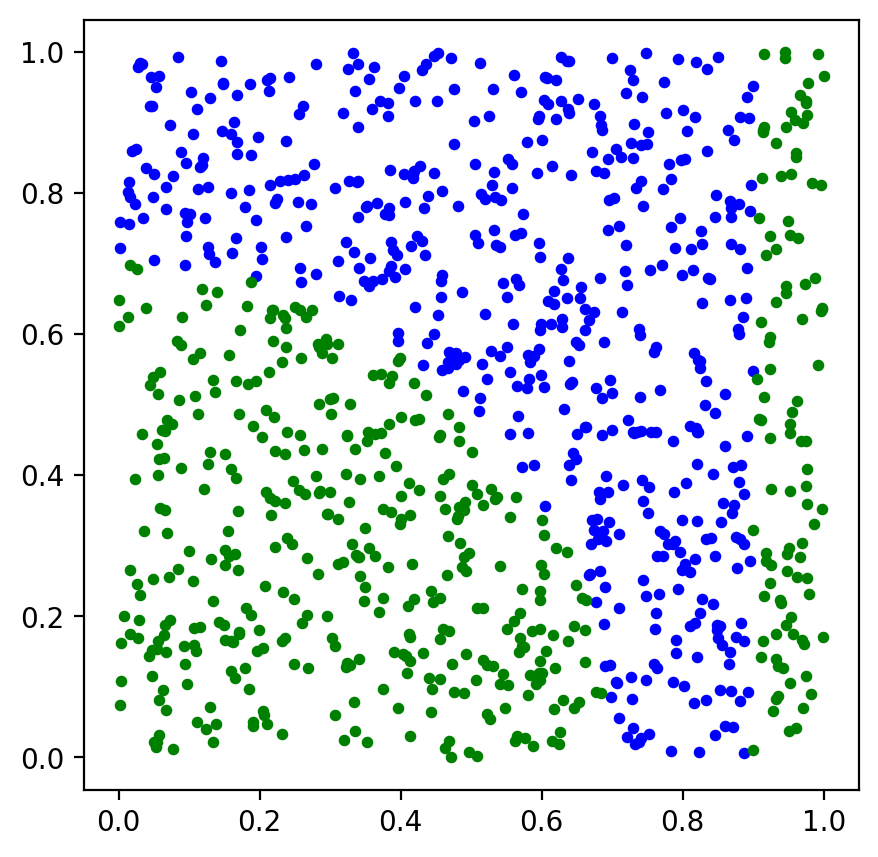

In [439]:
train_samples = crea_datos(NUM_PUNTOS_TRAIN)
datos=[[train_samples[0][i],train_samples[1][i],train_samples[2][i]] for i in range(NUM_PUNTOS_TRAIN)]
datos=np.array(datos).reshape(NUM_PUNTOS_TRAIN,3)
labels=np.array(train_samples[2:])
numpuntosplot=round(NUM_PUNTOS_ALL/10)
plot_data(datos[0:numpuntosplot])
test_samples = crea_datos(NUM_PUNTOS_TEST)

La red consiste en una capa de entrada de dos neuronas, una capa oculta de cuatro neuronas con función de activación sigmoidea o ReLU y una capa de salida con función sigmoidea.

## Inicialización de estructuras y hiperparámetros

Definimos los hiperparámetros del entrenamiento:

- **`learning_rate`**: tasa de aprendizaje $\eta$ para el descenso de gradiente.
- **`funcion_coste`**: función de coste a utilizar (`"mse"` o `"cross_entropy"`). La entropía cruzada es más adecuada para clasificación binaria con salida sigmoide.
- **`batch_length`**: tamaño de cada mini-batch en SGD.
- **`numepocas`**: número de pasadas completas por el conjunto de entrenamiento.

También creamos las estructuras auxiliares (vectores de activaciones, pre-activaciones y deltas) con la función `create_void_cols`.

In [440]:
def create_void_cols(dim):
    """Crea una lista de vectores de ceros. Cada elemento de 'dim' indica el tamaño
    del vector correspondiente. Se usa para inicializar activaciones, deltas y gradientes."""
    vcol = list()
    for i in dim:
        vcol.append( np.zeros(i,dtype=np.float64))
    return(vcol)

In [441]:
cost_train=np.zeros(NUM_PUNTOS_TRAIN)
learning_rate = 1                         # Tasa de aprendizaje. Si es pequeña (0.1) no funciona bien para las fronteras más complejas
funcion_coste = "cross_entropy"           # "mse" o "cross_entropy"
a = create_void_cols([2,4,1])             # Tensor de activaciones
z=copy.deepcopy(a)                        # Tensor de sumas ponderadas
z[0][0]= -1                               # El elemento 0 se inicializa a -1 porque no tiene sentido
z[0][1]= -1
d=copy.deepcopy(a)

## Inicialización de pesos

Los pesos se inicializan con distribuciones específicas según la función de activación de cada capa:

- **Capa oculta (ReLU)**: inicialización **He** — $w \sim \mathcal{N}\!\left(0,\, \sqrt{2/n_{\text{in}}}\right)$. Compensa que ReLU anula la mitad de las activaciones.
- **Capa de salida (sigmoid)**: inicialización **Xavier/Glorot** — $w \sim \mathcal{N}\!\left(0,\, \sqrt{1/n_{\text{in}}}\right)$. Mantiene la varianza de las activaciones en capas con funciones de activación saturantes.
- Los **sesgos** se inicializan a cero en ambas capas.

In [442]:
n0, n1, n2 = 2, 4, 1   # neuronas por capa

w = [np.array([0, 0])]
w.append(np.random.randn(n1, n0) * np.sqrt(2 / n0))   # He    — capa ReLU,     shape (4,2)
w.append(np.random.randn(n2, n1) * np.sqrt(1 / n1))   # Xavier — capa sigmoid, shape (1,4)

b = [np.array([0, 0])]
b.append(np.zeros(n1))
b.append(np.zeros(n2))

delta_l = create_void_cols([1,n1,1])           # Errores de cada neurona, para la retropropagación

## Funciones de activación y propagación

Definimos las funciones de activación y sus derivadas:

| Función | Fórmula | Derivada |
|---------|---------|----------|
| **Sigmoid** | $\sigma(z) = \frac{1}{1+e^{-z}}$ | $\sigma'(z) = \sigma(z)(1-\sigma(z))$ |
| **ReLU** | $\text{ReLU}(z) = \max(0, z)$ | $\text{ReLU}'(z) = \begin{cases}1 & z>0\\0 & z\leq 0\end{cases}$ |

La función **`NN_procesar`** aplica la activación correspondiente a cada capa (ReLU para la oculta, sigmoid para la salida).

In [443]:
def sigmoid(z):
    """Función de activación sigmoide: comprime cualquier valor real al intervalo (0,1)."""
    return(1.0 / (1.0+np.exp(-1*z)))

def ReLU(z):
    """Función de activación ReLU: devuelve z si z>0, cero en caso contrario."""
    mdatos = copy.deepcopy(z)
    for i in np.arange(len(mdatos)):
        if mdatos[i]<0:
            mdatos[i] = 0
    return(mdatos)

def NN_procesar(mya, myb, w, function="sigmoid"):
    """Calcula la salida de una capa: primero la suma ponderada z = w·a + b,
    luego aplica la función de activación indicada ('sigmoid' o 'ReLU').
    Devuelve (z, activación(z))."""
    mz = np.dot(w, mya) + myb
    if (function=="sigmoid"):
        return(mz,sigmoid(mz))
    if (function=="ReLU"):
        return(mz,ReLU(mz))

## Propagación hacia adelante (*forward propagation*)

La función `forward_prop` calcula la salida de la red para una entrada dada, capa por capa:

$$z^{[l]} = w^{[l]} \cdot a^{[l-1]} + b^{[l]}, \qquad a^{[l]} = g^{[l]}(z^{[l]})$$

donde $g^{[l]}$ es ReLU en la capa oculta y sigmoid en la capa de salida. Almacena todos los valores intermedios ($z$ y $a$) que luego necesitará la retropropagación.

In [444]:
def forward_prop(inp, b, w):
    """Propaga la entrada hacia adelante por las dos capas de la red:
    capa oculta con ReLU y capa de salida con sigmoid.
    Actualiza los tensores globales a (activaciones) y z (sumas ponderadas)."""
    global a,z
    z[1],a[1] = NN_procesar(inp,b[1],w[1],function="ReLU")
    z[2],a[2] = NN_procesar(a[1],b[2],w[2],function="sigmoid")
    return(z,a)

## Evaluación de la clasificación

La función `evaluar_clasificacion` recorre todas las muestras de un conjunto, propaga cada una por la red, aplica un umbral de 0.5 a la salida sigmoide para obtener la clase predicha (0 o 1) y cuenta los aciertos. Devuelve también la lista de predicciones para poder visualizar los errores.

In [445]:
def evaluar_clasificacion(samples, num_puntos_sample):
    """Recorre todas las muestras, hace una predicción con la red actual (umbral 0.5)
    y devuelve el número de aciertos y la lista de predicciones."""
    global a
    aciertos = 0
    predicciones = []
    for i in range(num_puntos_sample):
        a[0][0] = samples[0][i]
        a[0][1] = samples[1][i]
        z,a = forward_prop(a[0],b,w)
        pred = float(a[-1][0]>0.5)
        predicciones.append(pred)
        aciertos += pred == samples[2][i]
    return(aciertos,predicciones)

## Evaluación inicial (antes de entrenar)

Evaluamos la tasa de acierto de la red con los pesos aleatorios iniciales. Esto nos da una línea base: para un clasificador binario con clases equilibradas, esperamos alrededor de un 50% de acierto por azar. Cualquier mejora tras el entrenamiento se mide respecto a este valor.

In [446]:
# Evaluación del error de clasificación con los pesos aleatorios sobre el conjunto de entrenamiento
# Se usa solo como base para comparar
aciertos,predicciones = evaluar_clasificacion(train_samples, NUM_PUNTOS_TRAIN)
tasa_antes=(aciertos/NUM_PUNTOS_TRAIN)

In [447]:
print("Tasa de acierto antes de entrenar", tasa_antes)

Tasa de acierto antes de entrenar 0.582


## Retropropagación (*backpropagation*)

La función `backprop` calcula los gradientes $\nabla_w C$ y $\nabla_b C$ para **una sola muestra**, aplicando la regla de la cadena desde la capa de salida hasta la oculta:

1. **Capa de salida** ($L=2$):
   - Con **cross-entropy + sigmoid**: $\delta^L = a^L - y$ (la derivada $\sigma'$ se cancela).
   - Con **MSE**: $\delta^L = (a^L - y) \cdot \sigma'(z^L)$.
2. **Capa oculta** ($l=1$): $\delta^l = (w^{l+1})^\top \cdot \delta^{l+1} \odot \text{ReLU}'(z^l)$.
3. **Gradientes**: $\nabla_{w^l} C = \delta^l \cdot (a^{l-1})^\top$, $\nabla_{b^l} C = \delta^l$.

In [448]:
### Fórmulas de backprop
# d^L   = Grad_a C . s'(z^L)
# d^l   = (w^(l+1))T . d^(l+1) . s'(z^l)
# Grad_bj C    = d_j^l
# Grad_w_jk^l  = d_j^l . a_k^(l-1)

def sigmoid_derivada(z):
    """Derivada de la sigmoide: σ'(z) = σ(z)·(1−σ(z)). Necesaria en backprop."""
    return(sigmoid(z)*(1-sigmoid(z)))

def ReLU_derivada(z):
    """Derivada de ReLU: 1 si z>0, 0 en caso contrario. Necesaria en backprop."""
    mdatos = copy.deepcopy(z)
    mdatos = mdatos > 0  # ReLU derivada
    return(mdatos)

def cost_derivada(salidas, y):
    """Derivada del coste C=½(a−y)² respecto a la activación de salida: ∂C/∂a = a−y."""
    return (salidas-y)

def backprop(a, y, z, delta_l, b, w, funcion_coste="mse"):
    """Calcula los gradientes del coste para una muestra mediante retropropagación.
    funcion_coste: "mse" para C=½(a−y)², "cross_entropy" para C=−[y·log(a)+(1−y)·log(1−a)].
    Devuelve (∇w, ∇b, coste)."""
    eps = 1e-12
    d_nabla_b = [np.zeros(bs.shape) for bs in b]
    d_nabla_w = [np.zeros(mw.shape) for mw in w]
    if funcion_coste == "cross_entropy":
        a_clipped = np.clip(a[-1], eps, 1 - eps)
        cost = -(y * np.log(a_clipped) + (1 - y) * np.log(1 - a_clipped))
        # Con cross-entropy + sigmoid, δ^L = a − y (la σ' se cancela)
        delta_L = a[-1] - y
    else:
        cost = (1/2)*(a[-1]-y)**2
        # Con MSE, δ^L = (a − y) · σ'(z^L)
        delta_L = cost_derivada(a[-1],y) * sigmoid_derivada(z[-1])
    delta_l[-1] = delta_L
    d_nabla_b[-1] = delta_L
    d_nabla_w[-1] = np.outer(delta_L, a[-2])          # ∇w^L  = δ^L · (a^(L-1))ᵀ  shape (1,3)
    # Error en la capa oculta: δ^(L-1) = (w^L)ᵀ · δ^L ⊙ ReLU'(z^(L-1))
    delta_l[-2] = np.dot(w[-1].T, delta_l[-1]) * ReLU_derivada(z[-2])
    d_nabla_b[-2] = delta_l[-2]
    d_nabla_w[-2] = np.outer(delta_l[-2], a[-3])      # ∇w^(L-1) = δ^(L-1) · (a^0)ᵀ  shape (3,2)
    return d_nabla_w,d_nabla_b,cost[0]

## Entrenamiento: SGD por mini-batches

El bucle de entrenamiento implementa **descenso de gradiente estocástico (SGD)** con mini-batches:

1. En cada **época**, se barajan los datos aleatoriamente.
2. Se dividen en mini-batches de tamaño `batch_length`.
3. Para cada mini-batch, se acumulan los gradientes de todas sus muestras (llamando a `backprop` para cada una).
4. Se actualizan pesos y sesgos con el gradiente medio del batch:

$$w^{[l]} \leftarrow w^{[l]} - \frac{\eta}{|\text{batch}|} \sum_{i \in \text{batch}} \nabla_{w^{[l]}} C_i$$

Se imprime el coste medio cada 10 épocas para monitorizar la convergencia.

In [449]:
# SGD
batch_length = 100
numepocas=100
indices = list(range(NUM_PUNTOS_TRAIN))
history_cost = []
for ne in range(numepocas):
    random.shuffle(indices)
    for d in range(3):
        train_samples[d][:] = [train_samples[d][i] for i in indices]
    
    epoch_cost = 0.0
    nbatches = round(NUM_PUNTOS_TRAIN/batch_length)
    for binepoch in range(nbatches):
        d_nabla_b = [np.zeros(mb.shape) for mb in b]
        d_nabla_w = [np.zeros(mw.shape) for mw in w]
        for bsample in range(batch_length):
            k = binepoch*batch_length + bsample
            a[0][0] = train_samples[0][k]
            a[0][1] = train_samples[1][k]
            label=train_samples[2][k]
            z,a = forward_prop(a[0],b,w)
            dd_nabla_w,dd_nabla_b,mycost = backprop(a,label,z, delta_l, b, w, funcion_coste)
            d_nabla_b = [db+ddb for db, ddb in zip(d_nabla_b, dd_nabla_b)]
            d_nabla_w = [dw+ddw for dw, ddw in zip(d_nabla_w, dd_nabla_w)]
            epoch_cost+=mycost
        w=[weight-(learning_rate/batch_length)*dw for weight,dw in zip(w,d_nabla_w)]
        b=[bias-(learning_rate/batch_length)*db for bias,db in zip(b,d_nabla_b)]
    mean_cost = epoch_cost / NUM_PUNTOS_TRAIN
    history_cost.append(mean_cost)
    if (ne%10==0):    
        print(f"Epoca {ne}, Epoch cost {mean_cost:.04f}")

Epoca 0, Epoch cost 0.5500
Epoca 10, Epoch cost 0.4541
Epoca 20, Epoch cost 0.2566
Epoca 30, Epoch cost 0.1096
Epoca 40, Epoch cost 0.0753
Epoca 50, Epoch cost 0.0788
Epoca 60, Epoch cost 0.0753
Epoca 70, Epoch cost 0.0678
Epoca 80, Epoch cost 0.0630
Epoca 90, Epoch cost 0.0617


## Curva de aprendizaje

Representamos la evolución del coste medio por época. Una curva descendente indica que la red está aprendiendo. Si la curva se estanca en un valor alto, puede ser necesario ajustar hiperparámetros (tasa de aprendizaje, número de neuronas o épocas).

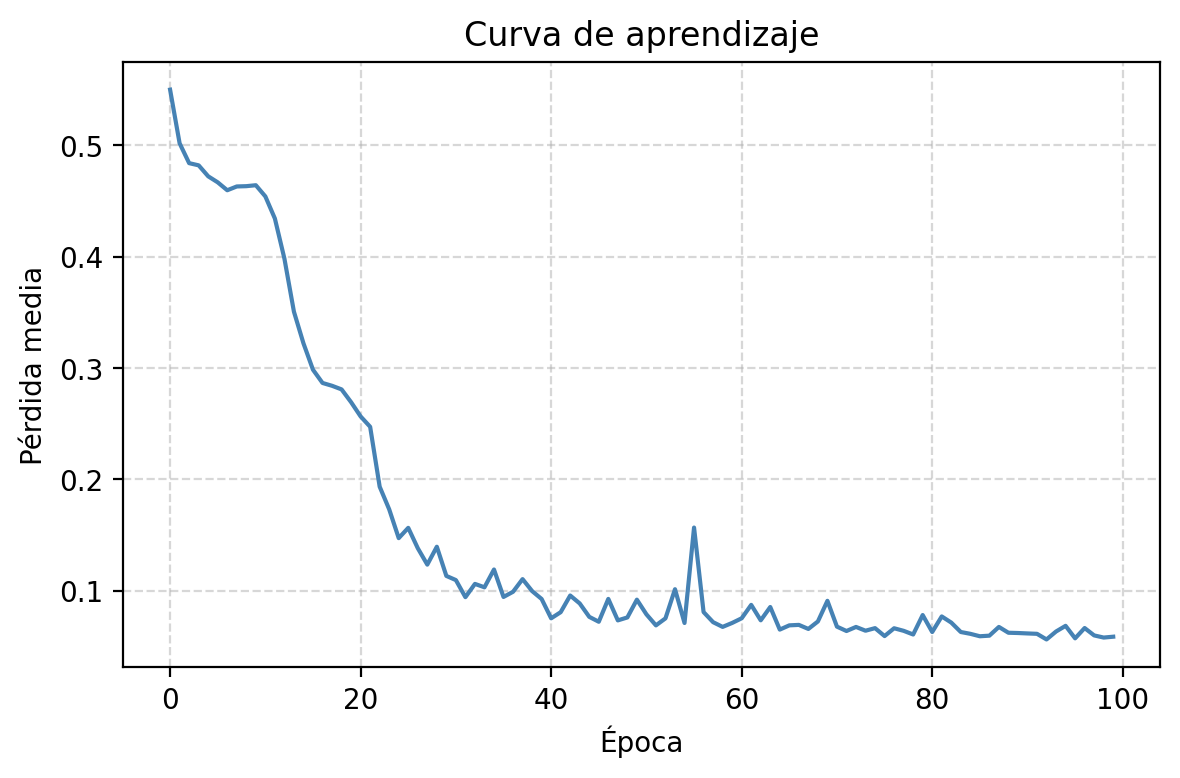

In [450]:
fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(history_cost, color="steelblue", linewidth=1.5)
ax.set_xlabel("Época")
ax.set_ylabel("Pérdida media")
ax.set_title("Curva de aprendizaje")
ax.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

## Evaluación en el conjunto de test

Medimos la capacidad de generalización de la red evaluándola sobre datos que **no ha visto durante el entrenamiento**. Si la tasa de acierto en test es similar a la de entrenamiento, la red generaliza bien; si es significativamente menor, puede haber *overfitting*.

In [451]:
aciertos, predicciones = evaluar_clasificacion(test_samples, NUM_PUNTOS_TEST)
tasa_test=(aciertos/NUM_PUNTOS_TEST)

In [452]:
print(aciertos)

1950


In [453]:
print("tasa de acierto en test",tasa_test)

tasa de acierto en test 0.975


## Visualización de los resultados en test

Dibujamos los puntos del conjunto de test coloreados según las predicciones de la red. Los puntos **rojos** indican errores de clasificación: muestras cuya clase predicha difiere de la real. Esto permite identificar visualmente en qué regiones del espacio la red tiene más dificultades.

In [454]:
numpuntosplot = min(1000,NUM_PUNTOS_TEST)
datos=[[test_samples[0][i],test_samples[1][i],test_samples[2][i]] for i in range(numpuntosplot)]
datos=np.array(datos).reshape(numpuntosplot,3)
labels=np.array(predicciones)[0:numpuntosplot]
fallos = 0
for i in range(numpuntosplot):
    if (labels[i] != test_samples[2][i]):
        fallos +=1
        labels[i] = 2

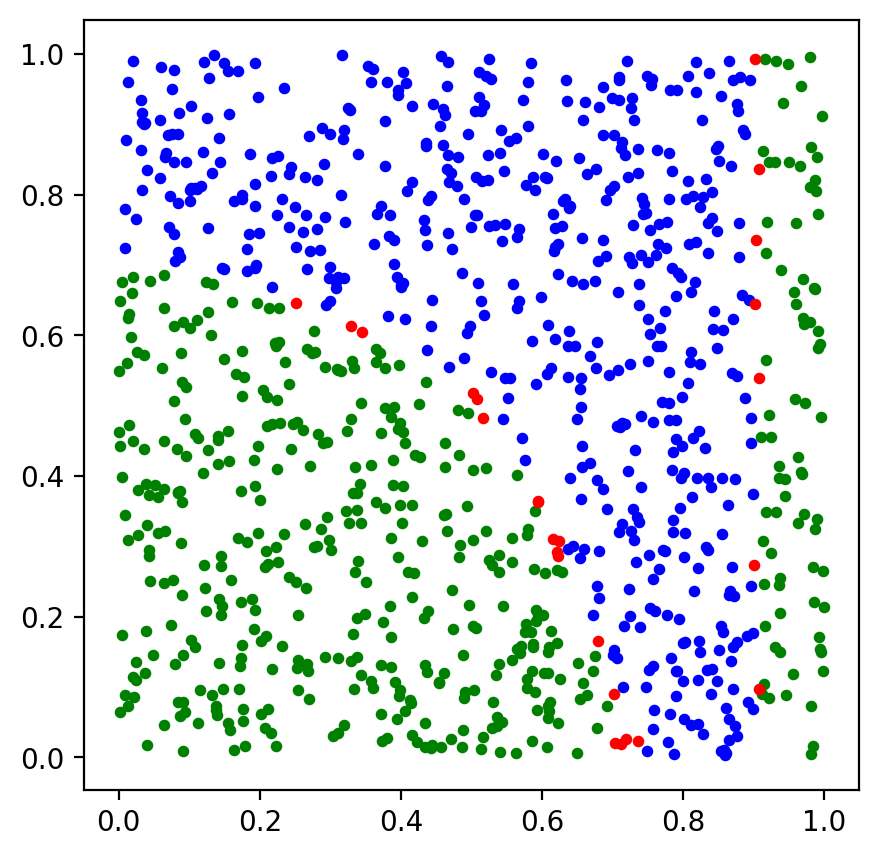

In [455]:
plot_data(datos,plabels=labels)


---

<font size="1" color="grey">
    (c) 2026 Javier García Algarra. <a href='https://www.u-tad.com'>www.u-tad.com</a> <br>
Licensed under a Creative Commons Reconocimiento 4.0 Internacional License
</font>